## Лабораторная 2

In [ ]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, make_scorer

In [ ]:
df = pd.read_csv("lab2/student_exam_scores.csv")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
print("Shape:", df.shape)
print('Первые 5 строк:')
from IPython.display import display
display(df.head())

Shape: (200, 6)
Первые 5 строк:


,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score
0,S001,8.0,8.8,72.1,45,30.2
1,S002,1.3,8.6,60.7,55,25.0
2,S003,4.0,8.2,73.7,86,35.8
3,S004,3.5,4.8,95.1,66,34.0
4,S005,9.1,6.4,89.8,71,40.3


In [ ]:
## One Hot Encoding
df['gender'] = np.random.choice([1, 0], size=len(df))


In [ ]:
# Создаём бинарную целевую переменную 'passed'
score_cols = ['exam_score']

df['avg_score'] = df[score_cols].mean(axis=1)
df['passed'] = (df['avg_score'] >= 32).astype(int)

# Признаки: демографические/категориальные
feature_cols = ['hours_studied', 'sleep_hours','gender','attendance_percent']
X = df[feature_cols].copy()
y = df['passed']

print("\nClass distribution (target):")
print(y.value_counts(normalize=True))

print("Shape:", df.shape)
display(df.head())



Class distribution (target):
passed
1    0.595
0    0.405
Name: proportion, dtype: float64
Shape: (200, 9)


,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score,gender,avg_score,passed
0,S001,8.0,8.8,72.1,45,30.2,0,30.2,0
1,S002,1.3,8.6,60.7,55,25.0,1,25.0,0
2,S003,4.0,8.2,73.7,86,35.8,0,35.8,1
3,S004,3.5,4.8,95.1,66,34.0,0,34.0,1
4,S005,9.1,6.4,89.8,71,40.3,0,40.3,1


In [ ]:

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# ----------------------------------------------------------------------------
# ----------------------------------------------------------------------------
# ----------------------------------------------------------------------------

preproc = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore'), feature_cols)
], remainder='drop')

clf = Pipeline([
    ('preproc', preproc),
    ('logreg', LogisticRegression(solver='liblinear', max_iter=1000, random_state=42))
])

# Метрики
scoring = ['accuracy', 'precision', 'recall', 'f1']

def compute_metrics_true(y_true, y_pred):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0)
    }

print("Shape исходного df:", df.shape)
display(df.head())


Shape исходного df: (200, 9)


,student_id,hours_studied,sleep_hours,attendance_percent,previous_scores,exam_score,gender,avg_score,passed
0,S001,8.0,8.8,72.1,45,30.2,0,30.2,0
1,S002,1.3,8.6,60.7,55,25.0,0,25.0,0
2,S003,4.0,8.2,73.7,86,35.8,0,35.8,1
3,S004,3.5,4.8,95.1,66,34.0,0,34.0,1
4,S005,9.1,6.4,89.8,71,40.3,1,40.3,1


## Валидация №1 -  Random Permutation(Cross Validation)

Результаты кросс-валидации:
{'fit_time': array([0.03770471, 0.01766825, 0.02718282, 0.04233718, 0.03412223]), 'score_time': array([0.09306812, 0.03270388, 0.0289669 , 0.04451632, 0.05528855]), 'test_accuracy': array([0.675, 0.6  , 0.725, 0.625, 0.625]), 'test_precision': array([0.67741935, 0.625     , 0.75      , 0.6875    , 0.61111111]), 'test_recall': array([0.875     , 0.83333333, 0.88888889, 0.81481481, 0.95652174]), 'test_f1': array([0.76363636, 0.71428571, 0.81355932, 0.74576271, 0.74576271]), 'test_rmse': array([nan, nan, nan, nan, nan])}

ShuffleSplit результаты (mean ± std):
accuracy : 0.6500 ± 0.0447
precision: 0.6702 ± 0.0495
recall   : 0.8737 ± 0.0494
f1       : 0.7566 ± 0.0326


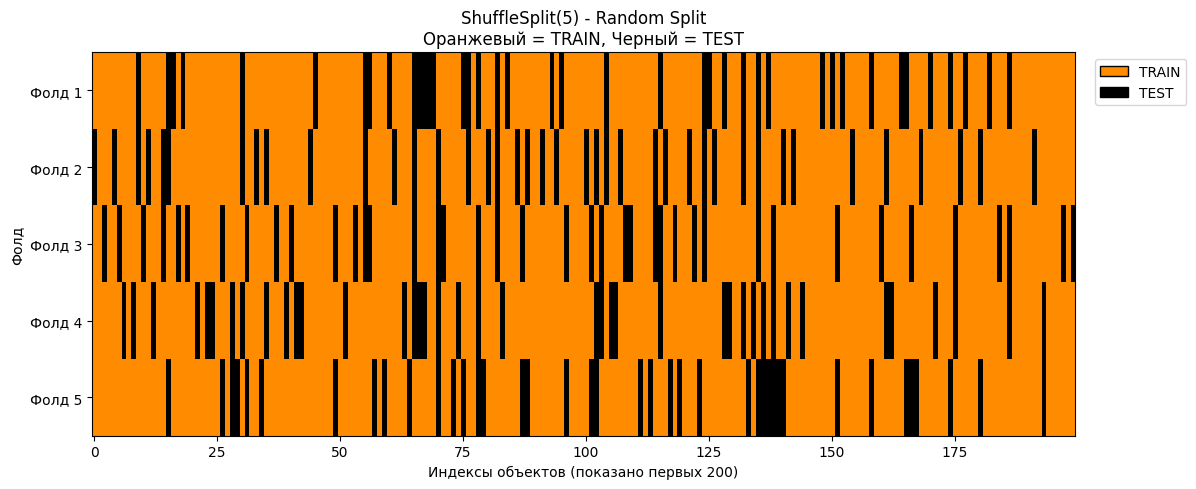

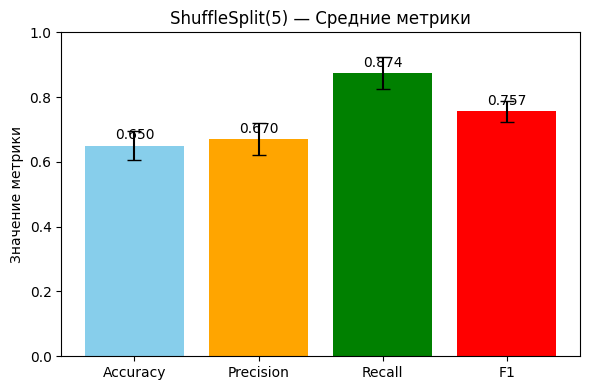


Сводная таблица метрик:


,Validation Type,Accuracy,Precision,Recall,F1
0,ShuffleSplit (5 splits),0.650000,0.670206,0.873712,0.756601
1,KFold (5) - shuffle=True,0.655000,0.671613,0.847130,0.745529
2,ShuffleSplit (5 splits),0.650000,0.670206,0.873712,0.756601
3,KFold (5) - shuffle=True,0.655000,0.671613,0.847130,0.745529
4,"StratifiedKFold (5, no shuffle)",0.665000,0.679640,0.839855,0.749166
5,"KFold (5, no shuffle)",0.650000,0.670709,0.824346,0.736704
6,Repeated Stratified KFold (5×3),0.646667,0.655084,0.860266,0.741671
7,"ShuffleSplit (10×, test=0.2)",0.655000,0.663164,0.877188,0.751490
8,ShuffleSplit (5 splits),0.650000,0.670206,0.873712,0.756601


In [ ]:
from sklearn.model_selection import ShuffleSplit, cross_validate
from sklearn.metrics import mean_squared_error, make_scorer, accuracy_score, precision_score, recall_score, f1_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap

# === 1) Настройки ===
NFOLDS = 5
SEED = 42
splitter = ShuffleSplit(n_splits=NFOLDS, train_size=0.7, test_size=0.2, random_state=SEED)

# Создаем несколько scorers для разных метрик
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'rmse': make_scorer(lambda y_true, y_pred: mean_squared_error(y_true, y_pred, squared=False))
}

# === 2) Кросс-валидация (Random Permutation CV) ===
cv_res_rpcv = cross_validate(
    clf, X, y,
    cv=splitter,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1
)

print("Результаты кросс-валидации:")
print(cv_res_rpcv)

# === 3) Считаем средние и отклонения ===
res_rpcv = {
    'cv': 'ShuffleSplit (5 splits)',
    'n_splits': len(cv_res_rpcv['test_accuracy']),
    'accuracy_mean': np.mean(cv_res_rpcv['test_accuracy']),
    'accuracy_std': np.std(cv_res_rpcv['test_accuracy']),
    'precision_mean': np.mean(cv_res_rpcv['test_precision']),
    'precision_std': np.std(cv_res_rpcv['test_precision']),
    'recall_mean': np.mean(cv_res_rpcv['test_recall']),
    'recall_std': np.std(cv_res_rpcv['test_recall']),
    'f1_mean': np.mean(cv_res_rpcv['test_f1']),
    'f1_std': np.std(cv_res_rpcv['test_f1']),
}

# Добавляем в общий results (если нет — создаём)
if 'results' not in globals():
    results = []
results.append(res_rpcv)

print("\nShuffleSplit результаты (mean ± std):")
print(f"accuracy : {res_rpcv['accuracy_mean']:.4f} ± {res_rpcv['accuracy_std']:.4f}")
print(f"precision: {res_rpcv['precision_mean']:.4f} ± {res_rpcv['precision_std']:.4f}")
print(f"recall   : {res_rpcv['recall_mean']:.4f} ± {res_rpcv['recall_std']:.4f}")
print(f"f1       : {res_rpcv['f1_mean']:.4f} ± {res_rpcv['f1_std']:.4f}")

# === 4) Добавляем в stats таблицу ===
if 'stats' not in globals():
    stats = pd.DataFrame(columns=['Validation Type', 'Accuracy', 'Precision', 'Recall', 'F1'])

stats = pd.concat([
    stats,
    pd.DataFrame([{
        'Validation Type': 'ShuffleSplit (5 splits)',
        'Accuracy': res_rpcv['accuracy_mean'],
        'Precision': res_rpcv['precision_mean'],
        'Recall': res_rpcv['recall_mean'],
        'F1': res_rpcv['f1_mean']
    }])
], ignore_index=True)

# === 5) Визуализация разбиений ===
splits = list(splitter.split(X, y))
n_samples = X.shape[0]
n_folds = len(splits)
mat = np.zeros((n_folds, n_samples), dtype=int)

for i, (train_idx, test_idx) in enumerate(splits):
    mat[i, train_idx] = 0  # train
    mat[i, test_idx] = 1   # test

max_display = 1000
x_display = min(n_samples, max_display)
mat_disp = mat[:, :x_display]

cmap = ListedColormap(['darkorange', 'black'])
fig, ax = plt.subplots(figsize=(12, 0.8 * n_folds + 1))
ax.imshow(mat_disp, aspect='auto', cmap=cmap, interpolation='nearest')
ax.set_xlabel(f"Индексы объектов (показано первых {x_display})")
ax.set_ylabel('Фолд')
ax.set_yticks(range(n_folds))
ax.set_yticklabels([f'Фолд {i+1}' for i in range(n_folds)])
ax.set_title('ShuffleSplit(5) - Random Split\nОранжевый = TRAIN, Черный = TEST')

legend_elements = [
    Patch(facecolor='darkorange', edgecolor='k', label='TRAIN'),
    Patch(facecolor='black', edgecolor='k', label='TEST')
]
ax.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.12, 1))
plt.tight_layout()
plt.show()

# === 6) Bar chart средних метрик ===
metrics_plot = {
    'Accuracy': res_rpcv['accuracy_mean'],
    'Precision': res_rpcv['precision_mean'],
    'Recall': res_rpcv['recall_mean'],
    'F1': res_rpcv['f1_mean']
}


fig, ax = plt.subplots(figsize=(6,4))
bars = ax.bar(metrics_plot.keys(), metrics_plot.values(),
              color=['skyblue','orange','green','red'],
              yerr=[res_rpcv['accuracy_std'], res_rpcv['precision_std'],
                    res_rpcv['recall_std'], res_rpcv['f1_std']],
              capsize=5)
ax.set_ylim(0, 1)
ax.set_title('ShuffleSplit(5) — Средние метрики')
ax.set_ylabel('Значение метрики')

# Добавляем значения на столбцы
for bar, val in zip(bars, metrics_plot.values()):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.3f}", ha='center')

plt.tight_layout()
plt.show()

# === 7) Вывод обновлённой таблицы stats ===
print("\nСводная таблица метрик:")
display(stats)


In [ ]:
from sklearn.model_selection import ShuffleSplit, cross_validate

NFOLDS = 5
SEED = 42
splitter = ShuffleSplit(n_splits=NFOLDS, train_size=0.7, test_size=0.2, random_state=SEED)

cv_res_rpcv = cross_validate(
    clf, X, y,
    cv=splitter,
    scoring=scoring,         # <- use the classification scoring dict
    return_train_score=False,
    n_jobs=-1
)

print(cv_res_rpcv.keys())  # sanity check

res_rpcv = {
    'cv': f'RandomPermutation ({NFOLDS})',
    'n_splits': len(cv_res_rpcv['test_accuracy']),
    'accuracy_mean': np.mean(cv_res_rpcv['test_accuracy']),
    'accuracy_std': np.std(cv_res_rpcv['test_accuracy']),
    'precision_mean': np.mean(cv_res_rpcv['test_precision']),
    'precision_std': np.std(cv_res_rpcv['test_precision']),
    'recall_mean': np.mean(cv_res_rpcv['test_recall']),
    'recall_std': np.std(cv_res_rpcv['test_recall']),
    'f1_mean': np.mean(cv_res_rpcv['test_f1']),
    'f1_std': np.std(cv_res_rpcv['test_f1']),
}

results.append(res_rpcv)
print(res_rpcv)


dict_keys(['fit_time', 'score_time', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_rmse'])
{'cv': 'RandomPermutation (5)', 'n_splits': 5, 'accuracy_mean': np.float64(0.7), 'accuracy_std': np.float64(0.05), 'precision_mean': np.float64(0.7164142771804062), 'precision_std': np.float64(0.05325673214592242), 'recall_mean': np.float64(0.8640901771336553), 'recall_std': np.float64(0.0317903925197186), 'f1_mean': np.float64(0.7822261021295497), 'f1_std': np.float64(0.03643106574458147)}


## Валидация №2 - KFold (shuffle)

{'fit_time': array([0.01149273, 0.00982213, 0.01970267, 0.01155686, 0.01027608]), 'score_time': array([0.02044272, 0.01914811, 0.02650881, 0.02119231, 0.01694345]), 'test_accuracy': array([0.775, 0.65 , 0.575, 0.625, 0.7  ]), 'test_precision': array([0.77777778, 0.61290323, 0.6       , 0.64285714, 0.75862069]), 'test_recall': array([0.875     , 0.9047619 , 0.875     , 0.7826087 , 0.81481481]), 'test_f1': array([0.82352941, 0.73076923, 0.71186441, 0.70588235, 0.78571429]), 'test_rmse': array([nan, nan, nan, nan, nan])}

KFold(5) results (mean ± std):
accuracy: 0.6650 ± 0.0682
precision: 0.6784 ± 0.0748
recall: 0.8504 ± 0.0448
f1: 0.7516 ± 0.0457


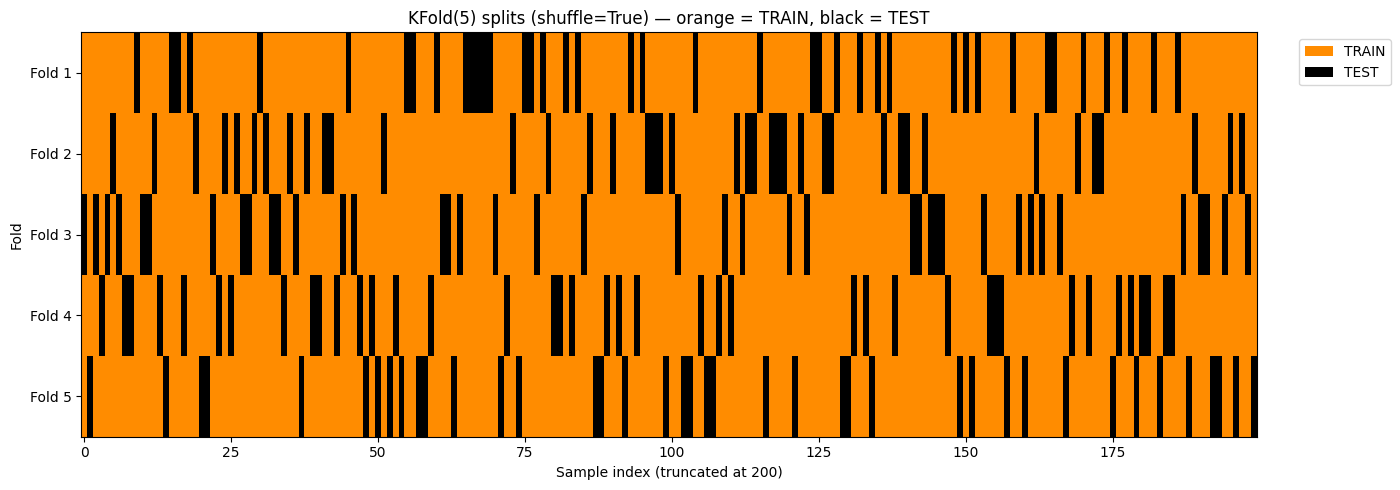

Total samples: 200 | Folds: 5 | Test size per fold (approx): 40


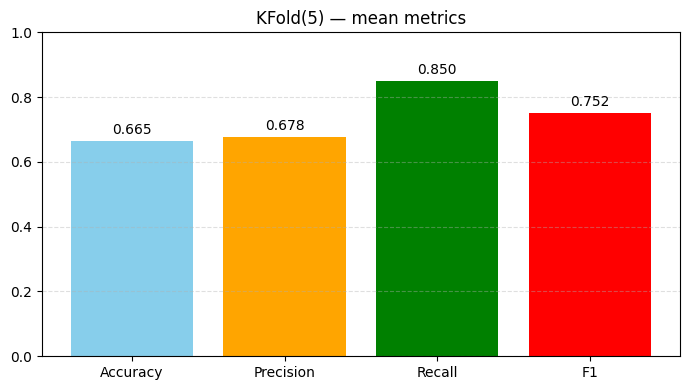


Per-fold metrics:


,fold,accuracy,precision,recall,f1
0,1,0.775,0.777778,0.875000,0.823529
1,2,0.650,0.612903,0.904762,0.730769
2,3,0.575,0.600000,0.875000,0.711864
3,4,0.625,0.642857,0.782609,0.705882
4,5,0.700,0.758621,0.814815,0.785714


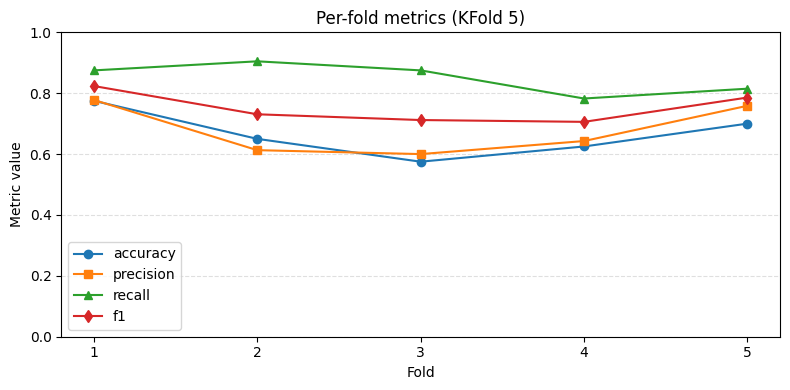


Stats summary :


,Validation Type,Accuracy,Precision,Recall,F1
0,ShuffleSplit (5 splits),0.650000,0.670206,0.873712,0.756601
1,KFold (5) - shuffle=True,0.655000,0.671613,0.847130,0.745529
2,ShuffleSplit (5 splits),0.650000,0.670206,0.873712,0.756601
3,KFold (5) - shuffle=True,0.655000,0.671613,0.847130,0.745529
4,"StratifiedKFold (5, no shuffle)",0.665000,0.679640,0.839855,0.749166
5,"KFold (5, no shuffle)",0.650000,0.670709,0.824346,0.736704
6,Repeated Stratified KFold (5×3),0.646667,0.655084,0.860266,0.741671
7,"ShuffleSplit (10×, test=0.2)",0.655000,0.663164,0.877188,0.751490
8,ShuffleSplit (5 splits),0.650000,0.670206,0.873712,0.756601
9,KFold (5) - shuffle=True,0.665000,0.678432,0.850437,0.751552


In [ ]:


from sklearn.model_selection import KFold, cross_validate
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap

# === Выполнение KFold и сбор метрик ===
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_res_kf = cross_validate(clf, X, y,
                           cv=kf, scoring=scoring, return_train_score=False,
                           n_jobs=-1)
print(cv_res_kf)
res_kf = {
    'cv': 'kfold (5)',
    'n_splits': len(cv_res_kf['test_accuracy']),
    'accuracy_mean': np.mean(cv_res_kf['test_accuracy']),
    'accuracy_std': np.std(cv_res_kf['test_accuracy']),
    'precision_mean': np.mean(cv_res_kf['test_precision']),
    'precision_std': np.std(cv_res_kf['test_precision']),
    'recall_mean': np.mean(cv_res_kf['test_recall']),
    'recall_std': np.std(cv_res_kf['test_recall']),
    'f1_mean': np.mean(cv_res_kf['test_f1']),
    'f1_std': np.std(cv_res_kf['test_f1']),
}
# Добавляем в общий results (если есть), иначе создаём
if 'results' not in globals():
    results = []
results.append(res_kf)

print("\nKFold(5) results (mean ± std):")
print(f"accuracy: {res_kf['accuracy_mean']:.4f} ± {res_kf['accuracy_std']:.4f}")
print(f"precision: {res_kf['precision_mean']:.4f} ± {res_kf['precision_std']:.4f}")
print(f"recall: {res_kf['recall_mean']:.4f} ± {res_kf['recall_std']:.4f}")
print(f"f1: {res_kf['f1_mean']:.4f} ± {res_kf['f1_std']:.4f}")

# === добавляем в stats таблицу для сравнения методов ===
if 'stats' not in globals():
    stats = pd.DataFrame(columns=['Validation Type', 'Accuracy', 'Precision', 'Recall', 'F1'])

stats = pd.concat([
    stats,
    pd.DataFrame([{
        'Validation Type': 'KFold (5) - shuffle=True',
        'Accuracy': res_kf['accuracy_mean'],
        'Precision': res_kf['precision_mean'],
        'Recall': res_kf['recall_mean'],
        'F1': res_kf['f1_mean']
    }])
], ignore_index=True)

n_samples = X.shape[0]
splits = list(kf.split(X))  # list of (train_idx, test_idx)
n_folds = len(splits)
mat = np.zeros((n_folds, n_samples), dtype=int)  # 0 -> train, 1 -> test
for i, (train_idx, test_idx) in enumerate(splits):
    mat[i, test_idx] = 1

max_display = 1000
x_display = min(n_samples, max_display)
mat_disp = mat[:, :x_display]

cmap = ListedColormap(['darkorange', 'black'])  # 0 -> darkorange (train), 1 -> black (test)
fig, ax = plt.subplots(figsize=(14, 0.8 * n_folds + 1))
ax.imshow(mat_disp, aspect='auto', cmap=cmap, interpolation='nearest')
ax.set_xlabel(f"Sample index (truncated at {x_display})")
ax.set_ylabel('Fold')
ax.set_yticks(range(n_folds))
ax.set_yticklabels([f'Fold {i+1}' for i in range(n_folds)])
ax.set_title('KFold(5) splits (shuffle=True) — orange = TRAIN, black = TEST')
legend_elements = [Patch(facecolor='darkorange', label='TRAIN'), Patch(facecolor='black', label='TEST')]
ax.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.12, 1))
plt.tight_layout()
plt.show()

print(f"Total samples: {n_samples} | Folds: {n_folds} | Test size per fold (approx): {int(n_samples / n_folds)}")

# === 4) Визуализация 2 — barplot средних метрик (как у Hold-out) ===
metrics_plot = {
    'Accuracy': res_kf['accuracy_mean'],
    'Precision': res_kf['precision_mean'],
    'Recall': res_kf['recall_mean'],
    'F1': res_kf['f1_mean']
}

fig, ax = plt.subplots(figsize=(7,4))
names = list(metrics_plot.keys())
values = list(metrics_plot.values())
bars = ax.bar(names, values, color=['skyblue','orange','green','red'])
ax.set_ylim(0, 1)
ax.set_title('KFold(5) — mean metrics')
ax.grid(axis='y', linestyle='--', alpha=0.4)
for bar, val in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.3f}", ha='center')
plt.tight_layout()
plt.show()


per_fold = pd.DataFrame({
    'fold': np.arange(1, n_folds + 1),
    'accuracy': cv_res_kf['test_accuracy'],
    'precision': cv_res_kf['test_precision'],
    'recall': cv_res_kf['test_recall'],
    'f1': cv_res_kf['test_f1']
})
print("\nPer-fold metrics:")
display(per_fold)

plt.figure(figsize=(8,4))
plt.plot(per_fold['fold'], per_fold['accuracy'], marker='o', label='accuracy')
plt.plot(per_fold['fold'], per_fold['precision'], marker='s', label='precision')
plt.plot(per_fold['fold'], per_fold['recall'], marker='^', label='recall')
plt.plot(per_fold['fold'], per_fold['f1'], marker='d', label='f1')
plt.xticks(per_fold['fold'])
plt.ylim(0,1)
plt.xlabel('Fold')
plt.ylabel('Metric value')
plt.title('Per-fold metrics (KFold 5)')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

# === 6) Показать таблицу stats ===
print("\nStats summary :")
display(stats)


## Валидация №3 - StratifiedKFold (No Shuffle)


StratifiedKFold(5, no shuffle) results (mean ± std):
accuracy : 0.6800 ± 0.0430
precision: 0.6889 ± 0.0438
recall   : 0.8569 ± 0.0345
f1       : 0.7620 ± 0.0195


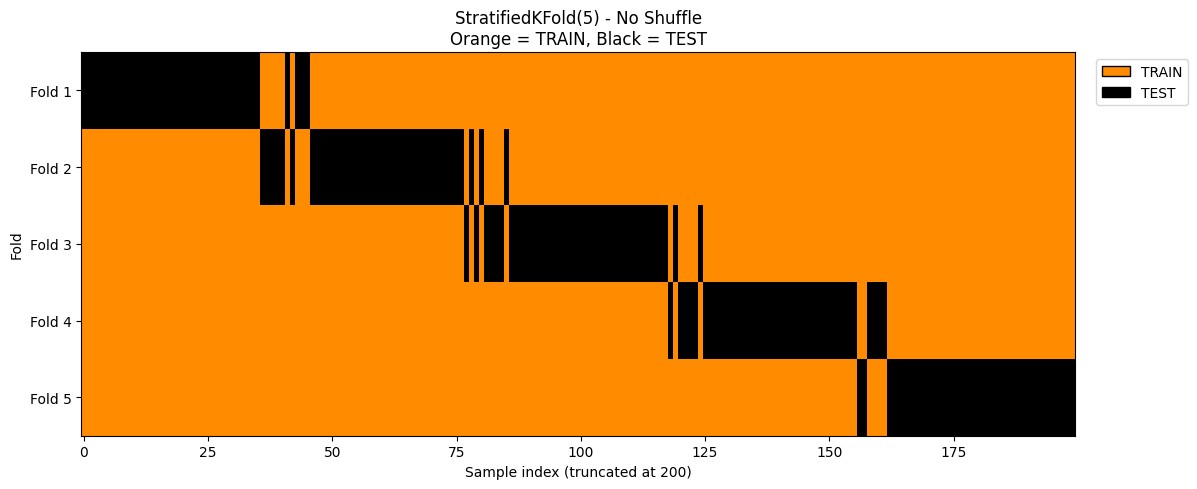

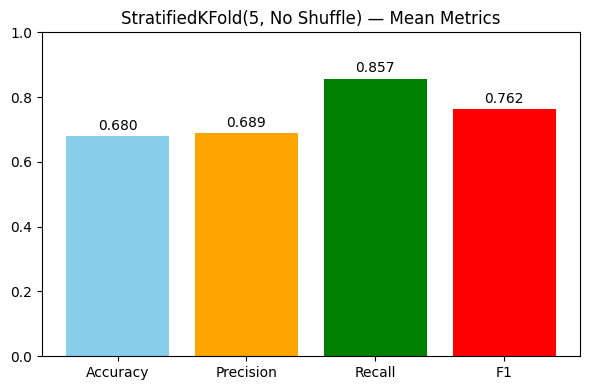


Stats summary :


,Validation Type,Accuracy,Precision,Recall,F1
0,ShuffleSplit (5 splits),0.675,0.681462,0.913889,0.777975
1,KFold (5) - shuffle=True,0.635,0.652314,0.848321,0.734400
2,"StratifiedKFold (5, no shuffle)",0.680,0.688942,0.856884,0.761951


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap
import pandas as pd

# === 1) Создаём StratifiedKFold (без shuffle) ===
skf_no_shuffle = StratifiedKFold(n_splits=5, shuffle=False)
cv_res_skf_no_shuffle = cross_validate(clf, X, y, cv=skf_no_shuffle, scoring=scoring, return_train_score=False, n_jobs=-1)

# === 2) Считаем средние и отклонения ===
res_skf_no_shuffle = {
    'cv': 'stratified_kfold (5, no shuffle)',
    'n_splits': len(cv_res_skf_no_shuffle['test_accuracy']),
    'accuracy_mean': np.mean(cv_res_skf_no_shuffle['test_accuracy']),
    'accuracy_std': np.std(cv_res_skf_no_shuffle['test_accuracy']),
    'precision_mean': np.mean(cv_res_skf_no_shuffle['test_precision']),
    'precision_std': np.std(cv_res_skf_no_shuffle['test_precision']),
    'recall_mean': np.mean(cv_res_skf_no_shuffle['test_recall']),
    'recall_std': np.std(cv_res_skf_no_shuffle['test_recall']),
    'f1_mean': np.mean(cv_res_skf_no_shuffle['test_f1']),
    'f1_std': np.std(cv_res_skf_no_shuffle['test_f1']),
}

# Добавляем в общий results (если нет — создаём)
if 'results' not in globals():
    results = []
results.append(res_skf_no_shuffle)

print("\nStratifiedKFold(5, no shuffle) results (mean ± std):")
print(f"accuracy : {res_skf_no_shuffle['accuracy_mean']:.4f} ± {res_skf_no_shuffle['accuracy_std']:.4f}")
print(f"precision: {res_skf_no_shuffle['precision_mean']:.4f} ± {res_skf_no_shuffle['precision_std']:.4f}")
print(f"recall   : {res_skf_no_shuffle['recall_mean']:.4f} ± {res_skf_no_shuffle['recall_std']:.4f}")
print(f"f1       : {res_skf_no_shuffle['f1_mean']:.4f} ± {res_skf_no_shuffle['f1_std']:.4f}")

# === 3) Добавляем в stats таблицу (как у KFold и Hold-out) ===
if 'stats' not in globals():
    stats = pd.DataFrame(columns=['Validation Type', 'Accuracy', 'Precision', 'Recall', 'F1'])

stats = pd.concat([
    stats,
    pd.DataFrame([{
        'Validation Type': 'StratifiedKFold (5, no shuffle)',
        'Accuracy': res_skf_no_shuffle['accuracy_mean'],
        'Precision': res_skf_no_shuffle['precision_mean'],
        'Recall': res_skf_no_shuffle['recall_mean'],
        'F1': res_skf_no_shuffle['f1_mean']
    }])
], ignore_index=True)

# === 4) Визуализация разбиений ===
splits = list(skf_no_shuffle.split(X, y))
n_samples = X.shape[0]
n_folds = len(splits)
mat = np.zeros((n_folds, n_samples), dtype=int)

for i, (train_idx, test_idx) in enumerate(splits):
    mat[i, train_idx] = 0  # train
    mat[i, test_idx] = 1   # test

max_display = 1000
x_display = min(n_samples, max_display)
mat_disp = mat[:, :x_display]

cmap = ListedColormap(['darkorange', 'black'])
fig, ax = plt.subplots(figsize=(12, 0.8 * n_folds + 1))
ax.imshow(mat_disp, aspect='auto', cmap=cmap, interpolation='nearest')
ax.set_xlabel(f"Sample index (truncated at {x_display})")
ax.set_ylabel('Fold')
ax.set_yticks(range(n_folds))
ax.set_yticklabels([f'Fold {i+1}' for i in range(n_folds)])
ax.set_title('StratifiedKFold(5) - No Shuffle\nOrange = TRAIN, Black = TEST')

legend_elements = [
    Patch(facecolor='darkorange', edgecolor='k', label='TRAIN'),
    Patch(facecolor='black', edgecolor='k', label='TEST')
]
ax.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.12, 1))
plt.tight_layout()
plt.show()

# === 5) Bar chart средних метрик ===
metrics_plot = {
    'Accuracy': res_skf_no_shuffle['accuracy_mean'],
    'Precision': res_skf_no_shuffle['precision_mean'],
    'Recall': res_skf_no_shuffle['recall_mean'],
    'F1': res_skf_no_shuffle['f1_mean']
}

fig, ax = plt.subplots(figsize=(6,4))
bars = ax.bar(metrics_plot.keys(), metrics_plot.values(), color=['skyblue','orange','green','red'])
ax.set_ylim(0, 1)
ax.set_title('StratifiedKFold(5, No Shuffle) — Mean Metrics')
for bar, val in zip(bars, metrics_plot.values()):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.3f}", ha='center')
plt.tight_layout()
plt.show()

# === 6) Вывод обновлённой таблицы stats ===
print("\nStats summary :")
display(stats)


## Валидация №4 - KFold (No Shuffle)


KFold(5, shuffle=False) results (mean ± std):
accuracy : 0.6250 ± 0.0474
precision: 0.6517 ± 0.0473
recall   : 0.8095 ± 0.0697
f1       : 0.7189 ± 0.0314


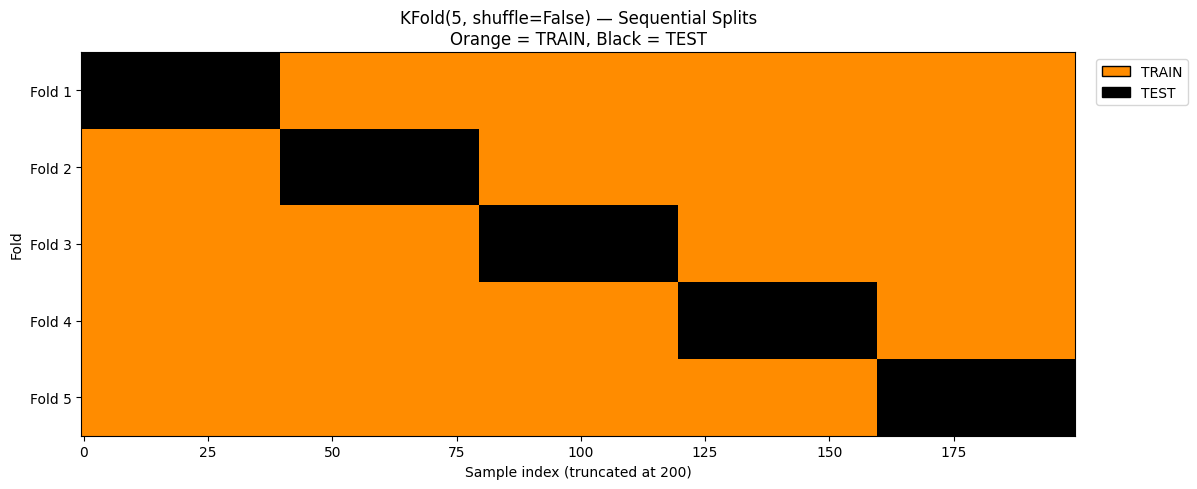

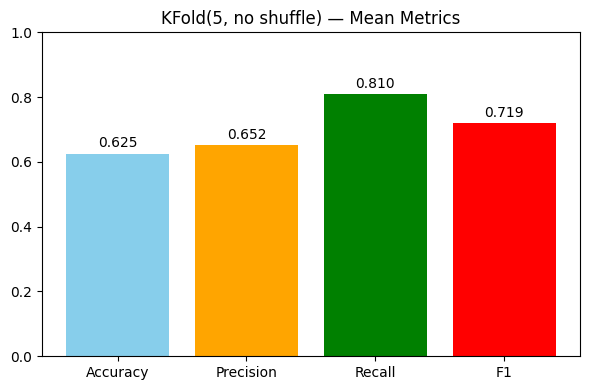


Stats summary :


,Validation Type,Accuracy,Precision,Recall,F1
0,ShuffleSplit (5 splits),0.675,0.681462,0.913889,0.777975
1,KFold (5) - shuffle=True,0.635,0.652314,0.848321,0.734400
2,"StratifiedKFold (5, no shuffle)",0.680,0.688942,0.856884,0.761951
3,"KFold (5, no shuffle)",0.625,0.651706,0.809531,0.718886


In [ ]:
from sklearn.model_selection import KFold, cross_validate
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap
import pandas as pd

# === 1) KFold без перемешивания ===
kf_no_shuffle = KFold(n_splits=5, shuffle=False)
cv_res_kf_no_shuffle = cross_validate(clf, X, y, cv=kf_no_shuffle, scoring=scoring, return_train_score=False, n_jobs=-1)

res_kf_no_shuffle = {
    'cv': 'kfold (5, no shuffle)',
    'n_splits': len(cv_res_kf_no_shuffle['test_accuracy']),
    'accuracy_mean': np.mean(cv_res_kf_no_shuffle['test_accuracy']),
    'accuracy_std': np.std(cv_res_kf_no_shuffle['test_accuracy']),
    'precision_mean': np.mean(cv_res_kf_no_shuffle['test_precision']),
    'precision_std': np.std(cv_res_kf_no_shuffle['test_precision']),
    'recall_mean': np.mean(cv_res_kf_no_shuffle['test_recall']),
    'recall_std': np.std(cv_res_kf_no_shuffle['test_recall']),
    'f1_mean': np.mean(cv_res_kf_no_shuffle['test_f1']),
    'f1_std': np.std(cv_res_kf_no_shuffle['test_f1']),
}

# === 2) Добавляем в общий список результатов ===
if 'results' not in globals():
    results = []
results.append(res_kf_no_shuffle)

print("\nKFold(5, shuffle=False) results (mean ± std):")
print(f"accuracy : {res_kf_no_shuffle['accuracy_mean']:.4f} ± {res_kf_no_shuffle['accuracy_std']:.4f}")
print(f"precision: {res_kf_no_shuffle['precision_mean']:.4f} ± {res_kf_no_shuffle['precision_std']:.4f}")
print(f"recall   : {res_kf_no_shuffle['recall_mean']:.4f} ± {res_kf_no_shuffle['recall_std']:.4f}")
print(f"f1       : {res_kf_no_shuffle['f1_mean']:.4f} ± {res_kf_no_shuffle['f1_std']:.4f}")

# === 3) Добавляем в stats таблицу ===
if 'stats' not in globals():
    stats = pd.DataFrame(columns=['Validation Type', 'Accuracy', 'Precision', 'Recall', 'F1'])

stats = pd.concat([
    stats,
    pd.DataFrame([{
        'Validation Type': 'KFold (5, no shuffle)',
        'Accuracy': res_kf_no_shuffle['accuracy_mean'],
        'Precision': res_kf_no_shuffle['precision_mean'],
        'Recall': res_kf_no_shuffle['recall_mean'],
        'F1': res_kf_no_shuffle['f1_mean']
    }])
], ignore_index=True)

# === 4) Визуализация разбиений ===
splits = list(kf_no_shuffle.split(X))
n_samples = X.shape[0]
n_folds = len(splits)
mat = np.zeros((n_folds, n_samples), dtype=int)
for i, (train_idx, test_idx) in enumerate(splits):
    mat[i, test_idx] = 1  # test

max_display = 1000
x_display = min(n_samples, max_display)
mat_disp = mat[:, :x_display]

cmap = ListedColormap(['darkorange', 'black'])
fig, ax = plt.subplots(figsize=(12, 0.8 * n_folds + 1))
ax.imshow(mat_disp, aspect='auto', cmap=cmap, interpolation='nearest')
ax.set_xlabel(f"Sample index (truncated at {x_display})")
ax.set_ylabel('Fold')
ax.set_yticks(range(n_folds))
ax.set_yticklabels([f'Fold {i+1}' for i in range(n_folds)])
ax.set_title('KFold(5, shuffle=False) — Sequential Splits\nOrange = TRAIN, Black = TEST')

legend_elements = [
    Patch(facecolor='darkorange', edgecolor='k', label='TRAIN'),
    Patch(facecolor='black', edgecolor='k', label='TEST')
]
ax.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.12, 1))
plt.tight_layout()
plt.show()

# === 5) Bar chart средних метрик ===
metrics_plot = {
    'Accuracy': res_kf_no_shuffle['accuracy_mean'],
    'Precision': res_kf_no_shuffle['precision_mean'],
    'Recall': res_kf_no_shuffle['recall_mean'],
    'F1': res_kf_no_shuffle['f1_mean']
}

fig, ax = plt.subplots(figsize=(6,4))
bars = ax.bar(metrics_plot.keys(), metrics_plot.values(), color=['skyblue','orange','green','red'])
ax.set_ylim(0, 1)
ax.set_title('KFold(5, no shuffle) — Mean Metrics')
for bar, val in zip(bars, metrics_plot.values()):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.3f}", ha='center')
plt.tight_layout()
plt.show()

# === 6) Печатаем обновлённую таблицу со всеми методами ===
print("\nStats summary :")
display(stats)


## Валидация №5 - Repeated Stratified K-Fold


Repeated Stratified K-Fold (5×3) results (mean ± std):
accuracy  : 0.6433 ± 0.0512
precision : 0.6559 ± 0.0374
recall    : 0.8460 ± 0.0769
f1        : 0.7373 ± 0.0431


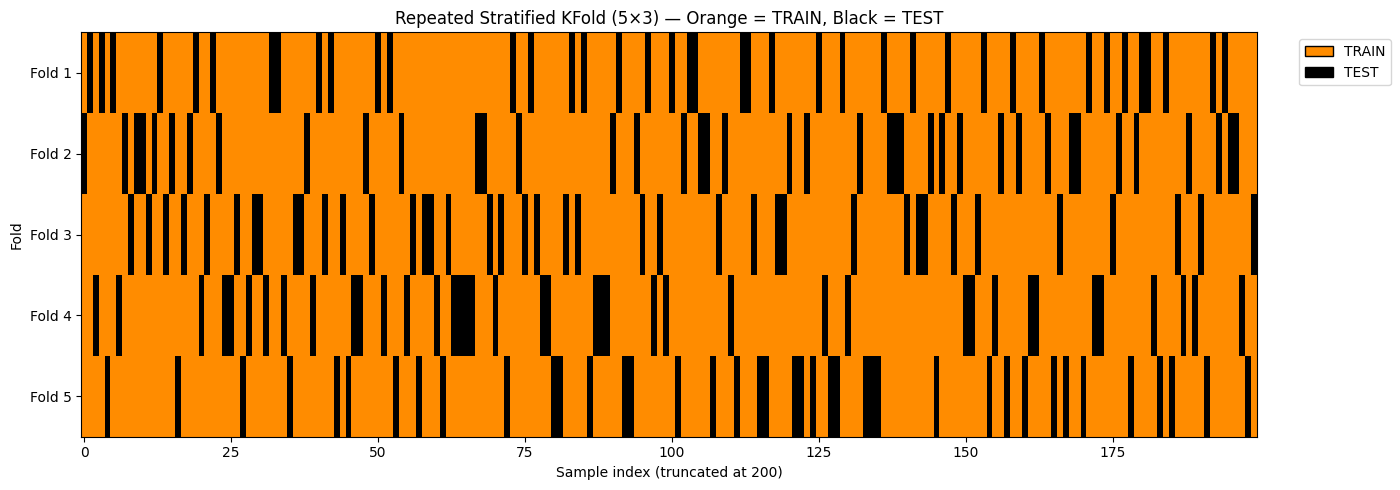

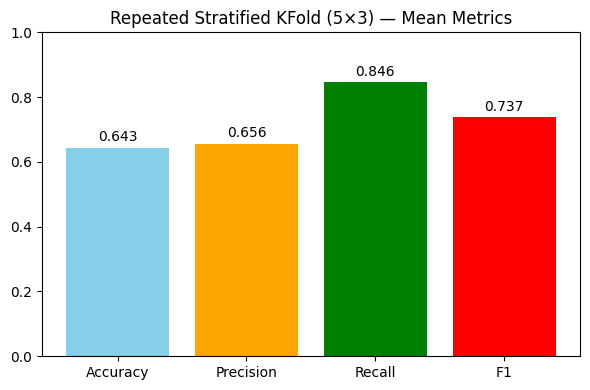


Stats summary (updated):


,Validation Type,Accuracy,Precision,Recall,F1
0,ShuffleSplit (5 splits),0.675000,0.681462,0.913889,0.777975
1,KFold (5) - shuffle=True,0.635000,0.652314,0.848321,0.734400
2,"StratifiedKFold (5, no shuffle)",0.680000,0.688942,0.856884,0.761951
3,"KFold (5, no shuffle)",0.625000,0.651706,0.809531,0.718886
4,Repeated Stratified KFold (5×3),0.643333,0.655887,0.846014,0.737342


In [ ]:

from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

# Выполняем cross_validate
cv_res_rskf = cross_validate(clf, X, y, cv=rskf, scoring=scoring, return_train_score=False, n_jobs=-1)

res_rskf = {
    'cv': 'Repeated Stratified KFold (5×3)',
    'n_splits': len(cv_res_rskf['test_accuracy']),
    'accuracy_mean': np.mean(cv_res_rskf['test_accuracy']),
    'accuracy_std': np.std(cv_res_rskf['test_accuracy']),
    'precision_mean': np.mean(cv_res_rskf['test_precision']),
    'precision_std': np.std(cv_res_rskf['test_precision']),
    'recall_mean': np.mean(cv_res_rskf['test_recall']),
    'recall_std': np.std(cv_res_rskf['test_recall']),
    'f1_mean': np.mean(cv_res_rskf['test_f1']),
    'f1_std': np.std(cv_res_rskf['test_f1']),
}
results.append(res_rskf)

print("\nRepeated Stratified K-Fold (5×3) results (mean ± std):")
for metric in ['accuracy', 'precision', 'recall', 'f1']:
    print(f"{metric:10s}: {res_rskf[f'{metric}_mean']:.4f} ± {res_rskf[f'{metric}_std']:.4f}")

# === Добавляем в таблицу stats ===
stats = pd.concat([
    stats,
    pd.DataFrame([{
        'Validation Type': 'Repeated Stratified KFold (5×3)',
        'Accuracy': res_rskf['accuracy_mean'],
        'Precision': res_rskf['precision_mean'],
        'Recall': res_rskf['recall_mean'],
        'F1': res_rskf['f1_mean']
    }])
], ignore_index=True)

# === Визуализация разбиений ===
splits = list(rskf.split(X, y))
n_samples = X.shape[0]
n_display = 5
mat = np.zeros((n_display, n_samples), dtype=int)

for i, (train_idx, test_idx) in enumerate(splits[:n_display]):
    mat[i, test_idx] = 1

max_display = 1000
x_display = min(n_samples, max_display)
mat_disp = mat[:, :x_display]

cmap = ListedColormap(['darkorange', 'black'])
fig, ax = plt.subplots(figsize=(14, 0.8 * n_display + 1))
ax.imshow(mat_disp, aspect='auto', cmap=cmap, interpolation='nearest')
ax.set_xlabel(f"Sample index (truncated at {x_display})")
ax.set_ylabel('Fold')
ax.set_yticks(range(n_display))
ax.set_yticklabels([f'Fold {i+1}' for i in range(n_display)])
ax.set_title('Repeated Stratified KFold (5×3) — Orange = TRAIN, Black = TEST')
legend_elements = [
    Patch(facecolor='darkorange', edgecolor='k', label='TRAIN'),
    Patch(facecolor='black', edgecolor='k', label='TEST')
]
ax.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.12, 1))
plt.tight_layout()
plt.show()

# === Bar chart метрик ===
metrics_plot = {
    'Accuracy': res_rskf['accuracy_mean'],
    'Precision': res_rskf['precision_mean'],
    'Recall': res_rskf['recall_mean'],
    'F1': res_rskf['f1_mean']
}

fig, ax = plt.subplots(figsize=(6,4))
bars = ax.bar(metrics_plot.keys(), metrics_plot.values(), color=['skyblue','orange','green','red'])
ax.set_ylim(0, 1)
ax.set_title('Repeated Stratified KFold (5×3) — Mean Metrics')
for bar, val in zip(bars, metrics_plot.values()):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.3f}", ha='center')
plt.tight_layout()
plt.show()

# === Вывод обновлённой таблицы stats ===
print("\nStats summary (updated):")
display(stats)


## Валидация №6 - ShuffleSplit (Monte Carlo)


ShuffleSplit (10×, test=0.2) results (mean ± std):
accuracy  : 0.6375 ± 0.0682
precision : 0.6495 ± 0.0805
recall    : 0.8772 ± 0.0528
f1        : 0.7420 ± 0.0499


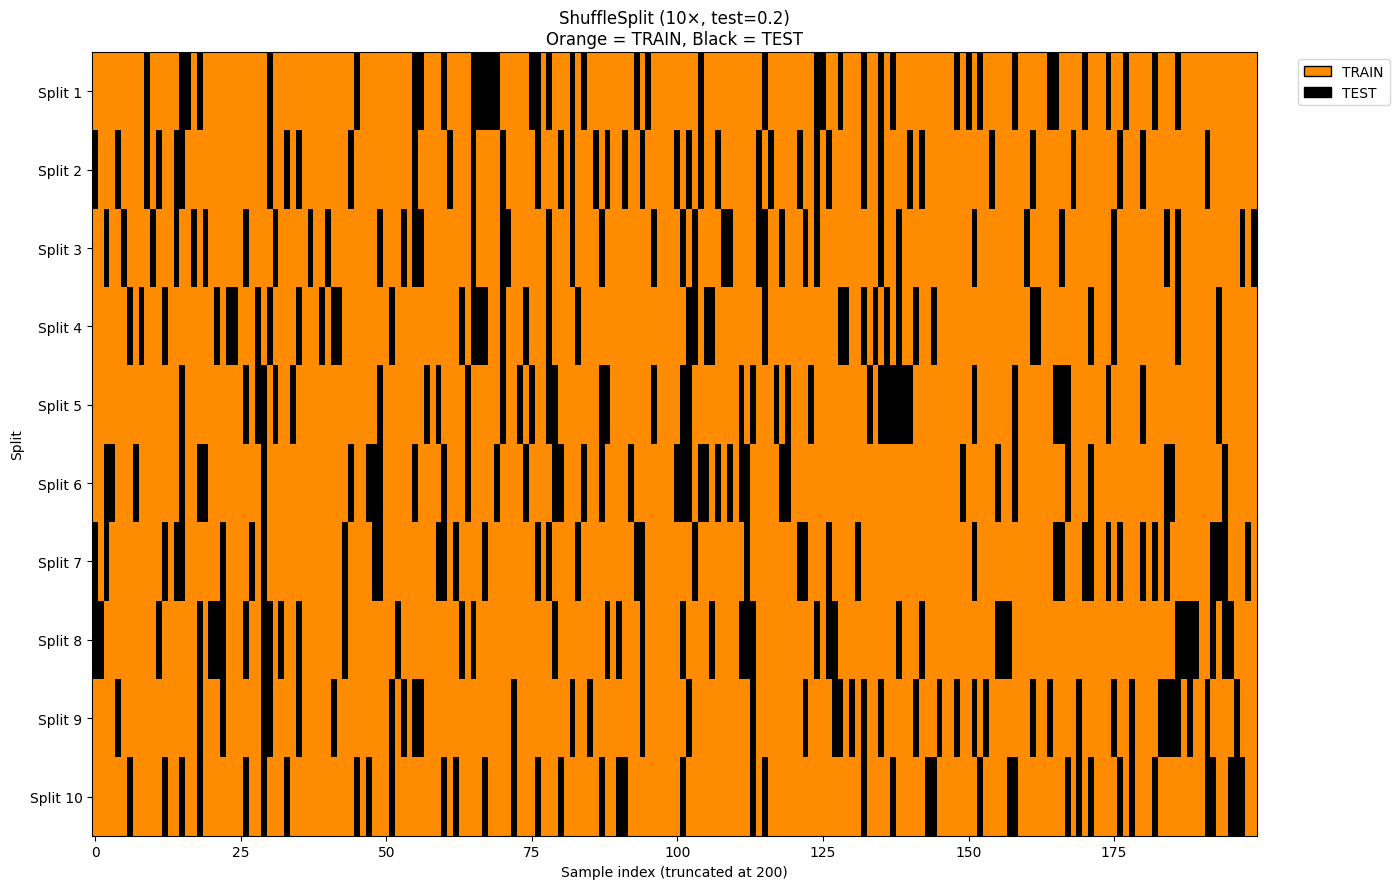

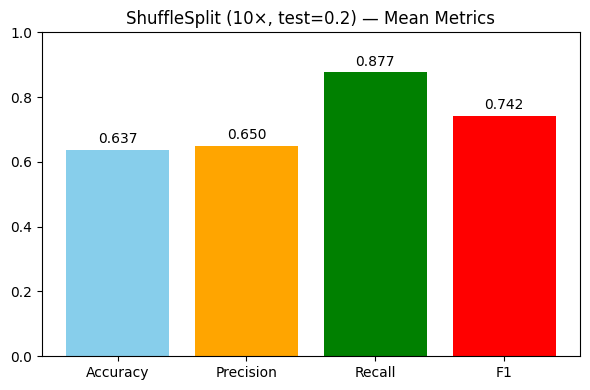


Stats summary (final):


,Validation Type,Accuracy,Precision,Recall,F1
0,ShuffleSplit (5 splits),0.675000,0.681462,0.913889,0.777975
1,KFold (5) - shuffle=True,0.635000,0.652314,0.848321,0.734400
2,"StratifiedKFold (5, no shuffle)",0.680000,0.688942,0.856884,0.761951
3,"KFold (5, no shuffle)",0.625000,0.651706,0.809531,0.718886
4,Repeated Stratified KFold (5×3),0.643333,0.655887,0.846014,0.737342
5,"ShuffleSplit (10×, test=0.2)",0.637500,0.649512,0.877188,0.741957


In [ ]:
# == ShuffleSplit  ==
from sklearn.model_selection import ShuffleSplit, cross_validate
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap

ss = ShuffleSplit(n_splits=10, test_size=0.2, random_state=42)

# cross_validate
cv_res_ss = cross_validate(clf, X, y, cv=ss, scoring=scoring, return_train_score=False, n_jobs=-1)

# === Подсчёт средних и стандартных отклонений ===
res_ss = {
    'cv': 'ShuffleSplit (10×, test=0.2)',
    'n_splits': len(cv_res_ss['test_accuracy']),
    'accuracy_mean': np.mean(cv_res_ss['test_accuracy']),
    'accuracy_std': np.std(cv_res_ss['test_accuracy']),
    'precision_mean': np.mean(cv_res_ss['test_precision']),
    'precision_std': np.std(cv_res_ss['test_precision']),
    'recall_mean': np.mean(cv_res_ss['test_recall']),
    'recall_std': np.std(cv_res_ss['test_recall']),
    'f1_mean': np.mean(cv_res_ss['test_f1']),
    'f1_std': np.std(cv_res_ss['test_f1']),
}
results.append(res_ss)

print("\nShuffleSplit (10×, test=0.2) results (mean ± std):")
for metric in ['accuracy', 'precision', 'recall', 'f1']:
    print(f"{metric:10s}: {res_ss[f'{metric}_mean']:.4f} ± {res_ss[f'{metric}_std']:.4f}")

# === Добавляем в таблицу stats ===
stats = pd.concat([
    stats,
    pd.DataFrame([{
        'Validation Type': 'ShuffleSplit (10×, test=0.2)',
        'Accuracy': res_ss['accuracy_mean'],
        'Precision': res_ss['precision_mean'],
        'Recall': res_ss['recall_mean'],
        'F1': res_ss['f1_mean']
    }])
], ignore_index=True)

# === Визуализация разбиений ===
splits = list(ss.split(X))
n_samples = X.shape[0]
n_folds = len(splits)
mat = np.zeros((n_folds, n_samples), dtype=int)

for i, (train_idx, test_idx) in enumerate(splits):
    mat[i, test_idx] = 1

max_display = 1000
x_display = min(n_samples, max_display)
mat_disp = mat[:, :x_display]

cmap = ListedColormap(['darkorange', 'black'])
fig, ax = plt.subplots(figsize=(14, 0.8 * n_folds + 1))
ax.imshow(mat_disp, aspect='auto', cmap=cmap, interpolation='nearest')
ax.set_xlabel(f"Sample index (truncated at {x_display})")
ax.set_ylabel('Split')
ax.set_yticks(range(n_folds))
ax.set_yticklabels([f'Split {i+1}' for i in range(n_folds)])
ax.set_title('ShuffleSplit (10×, test=0.2)\nOrange = TRAIN, Black = TEST')

legend_elements = [
    Patch(facecolor='darkorange', edgecolor='k', label='TRAIN'),
    Patch(facecolor='black', edgecolor='k', label='TEST')
]
ax.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.12, 1))
plt.tight_layout()
plt.show()

# === Bar chart метрик ===
metrics_plot = {
    'Accuracy': res_ss['accuracy_mean'],
    'Precision': res_ss['precision_mean'],
    'Recall': res_ss['recall_mean'],
    'F1': res_ss['f1_mean']
}

fig, ax = plt.subplots(figsize=(6,4))
bars = ax.bar(metrics_plot.keys(), metrics_plot.values(), color=['skyblue','orange','green','red'])
ax.set_ylim(0, 1)
ax.set_title('ShuffleSplit (10×, test=0.2) — Mean Metrics')
for bar, val in zip(bars, metrics_plot.values()):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.02, f"{val:.3f}", ha='center')
plt.tight_layout()
plt.show()

# === 6) Вывод обновлённой таблицы stats ===
print("\nStats summary (final):")
display(stats)
